# Ben Wisinski
## Analysis Report - Data in EMAT 11/15/26
--------------------------------------------------------------------------------------------------------------------------------------------
## Dataset
#### World Countries Link (https://jsonlint.com/datasets/countries)

I chose this dataset because I am intrested in world pollitics and population counts as well as the fact that it fulfills all of the requirements for this assignment. 

### *Note that this Data Set Only include 51 Countries*

## Observation Schema

**name**	string	Country name in English	"United States"

**code**	string	ISO 3166-1 alpha-2 code	"US"

**capital**	string	Capital city	"Washington, D.C."

**region**	string	Geographic region	"Americas"

**population**	number	Population estimate	331002651

**currency**	string	Currency code (ISO 4217)	"USD"

The Varibles that I plan to use to investigate are Name, Region & Population as well as potentially Currency

## Research Question 

Which region is home to the largest population, does that region have the most countries included in the data set & are those countries' population on average larger than others? What is the percentace of the population as a whole that this region makes up? Is there a standard currency that is used by that region?

### Hypothesis 

I believe that the region with the largest population is Asia and if I feel that it makes up roughly 50% of the worlds population I would also assume that Asia includes the most countries within this data set. I do not think that Asia has a standard currency.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

#Importing the librarys that will be used for creating data frames as well as charts

In [6]:
# Used the provided Import request code for the API

import requests

data = requests.get('https://jsonlint.com/datasets/countries.json').json()

# Create a lookup by country code
by_code = {c['code']: c for c in data['countries']}
print(by_code['GB']['capital'])  # "London"

# Get total world population (from this dataset)
total = sum(c['population'] for c in data['countries'])

London


In [9]:
print(total)
# This Gives a Base line for the total estimated population size of the 51 countries included in this dataset (5,968,270,113)

5968270113


In [21]:
data.keys() #using data.keys() I find out what is stored within the data and it is a dictionary titled countries

dict_keys(['countries'])

In [26]:
data['countries'][:5] #using the dictionary, I create a head without using data frames in order to find out what is 
                      #stored within the dictionary

[{'name': 'Afghanistan',
  'code': 'AF',
  'capital': 'Kabul',
  'region': 'Asia',
  'population': 38928346,
  'currency': 'AFN'},
 {'name': 'Albania',
  'code': 'AL',
  'capital': 'Tirana',
  'region': 'Europe',
  'population': 2877797,
  'currency': 'ALL'},
 {'name': 'Algeria',
  'code': 'DZ',
  'capital': 'Algiers',
  'region': 'Africa',
  'population': 43851044,
  'currency': 'DZD'},
 {'name': 'Argentina',
  'code': 'AR',
  'capital': 'Buenos Aires',
  'region': 'Americas',
  'population': 45195774,
  'currency': 'ARS'},
 {'name': 'Australia',
  'code': 'AU',
  'capital': 'Canberra',
  'region': 'Oceania',
  'population': 25499884,
  'currency': 'AUD'}]

In [56]:
#Tidys up data frame, and select only the relevant columns to be included

countries_df = pd.DataFrame(data['countries'])
countries_df = countries_df[['name','region','population','currency']]
countries_df.head()

,name,region,population,currency
0,Afghanistan,Asia,38928346,AFN
1,Albania,Europe,2877797,ALL
2,Algeria,Africa,43851044,DZD
3,Argentina,Americas,45195774,ARS
4,Australia,Oceania,25499884,AUD


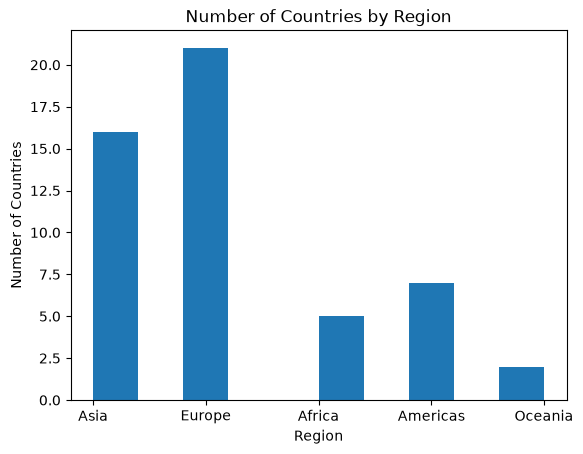

In [34]:
plt.hist(countries_df['region']) #Uses Matplotlib to call the region information from the created dataframe

plt.xlabel('Region')#names the x axis
plt.ylabel('Number of Countries')#names the y axis
plt.title('Number of Countries by Region')#names the title
plt.show()

---

The distribution of countries looks like the majority of countries included in the state are from Asia and Europe, which I would expect. I expect there to be a few countries from Americas and Oceania however I'm surprised that there are so few from Africa. This also immediately disproves my original idea that the most countries included would be from the Asia region. Because I'm using the regional bin that only includes information surrounding the number of countries it is a very easily digestible graph.

---


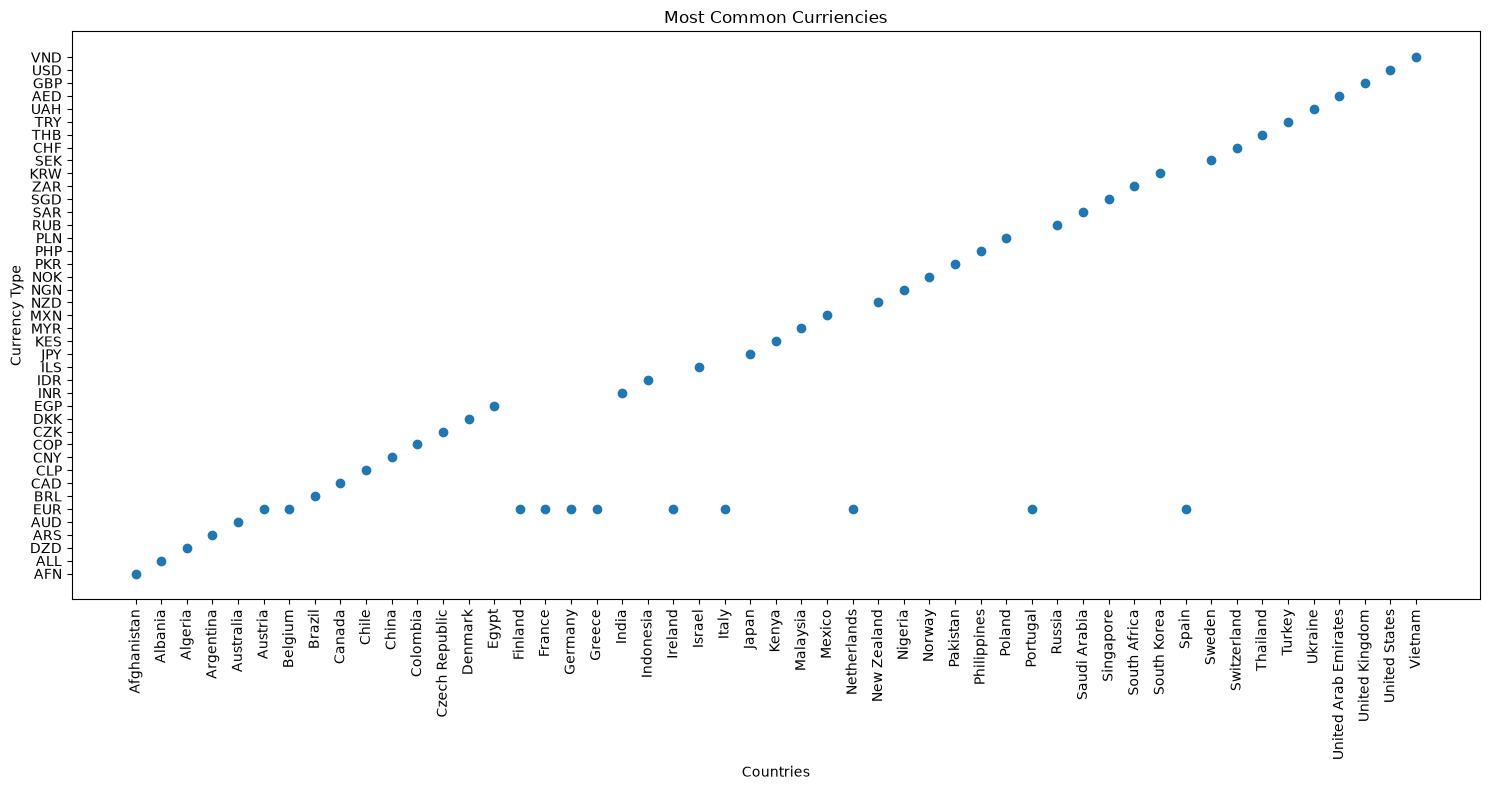

In [150]:
plt.figure(figsize=(15,8))# Makes the Graph Larger to fit all of the information

plt.scatter(countries_df['name'], # Creates Scatter Graph with name and currency for countries
            countries_df['currency'])

plt.xlabel('Countries') # X axis lable
plt.ylabel('Currency Type')# Y axis lable
plt.title('Most Common Curriencies') # Graph Title
plt.xticks(rotation=90)# Rotates X Axis Labels so you can read them

plt.tight_layout()# Tightens layout to fit better due to large amount fo x and y axis items
plt.show()

---

When looking at the results of this scatter graph it is interesting to note that the only overlap in currencies is the Euro with  11 with in the European Region. This combined with the fact that greatest number of countrys is in Europe likly means that this data set is fairly Euro-Centric

---

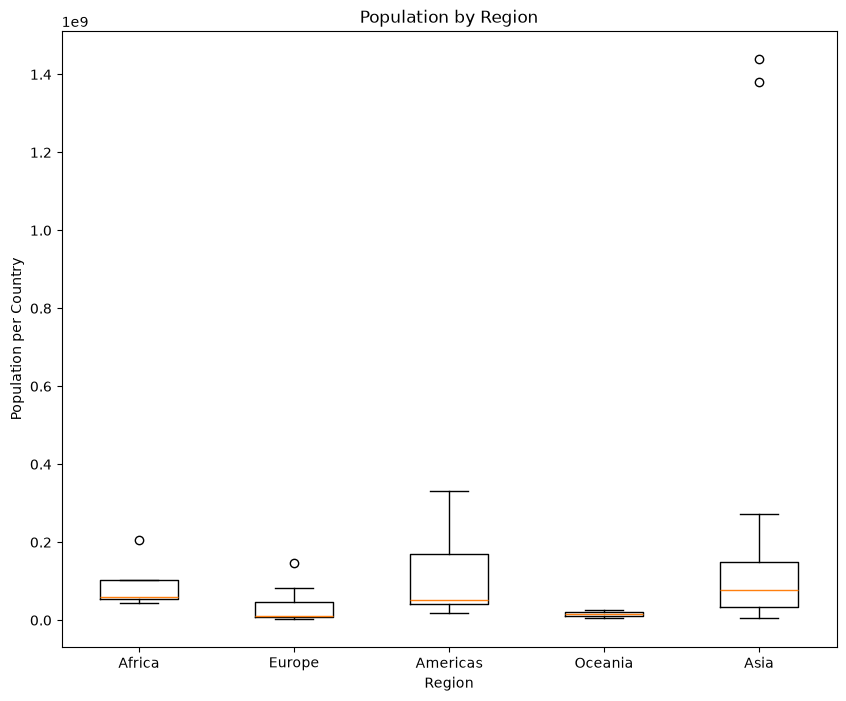

In [152]:
plt.figure(figsize=(10,8))# Makes the Graph Larger to fit all of the information

# Creates Varibles that containt the population info of countries with in each region
Africa = countries_df[countries_df['region'] == 'Africa']['population']
Europe = countries_df[countries_df['region'] == 'Europe']['population']
Americas = countries_df[countries_df['region'] == 'Americas']['population']
Oceania = countries_df[countries_df['region'] == 'Oceania']['population']
Asia = countries_df[countries_df['region'] == 'Asia']['population']

# Creates a boxplot using the Regional Population Varibles then names the diffrent charts accordingly
plt.boxplot( [Africa, Europe, Americas, Oceania, Asia],
    tick_labels=["Africa","Europe","Americas","Oceania","Asia"])

# Titles Graph Elements
plt.xlabel("Region")
plt.ylabel("Population per Country")
plt.title("Population by Region")

plt.show()

---

The boxplot reveals that on average countries with in the Americas, Afica & Asia have the highest population however there is also outliers with in Africa, Europe and Asia. Since their are two outliers that are the highest outliers in Asia and Asia already has the highest average population count per country it lends support to my orginal hypothesis of Asia having the highest population

---

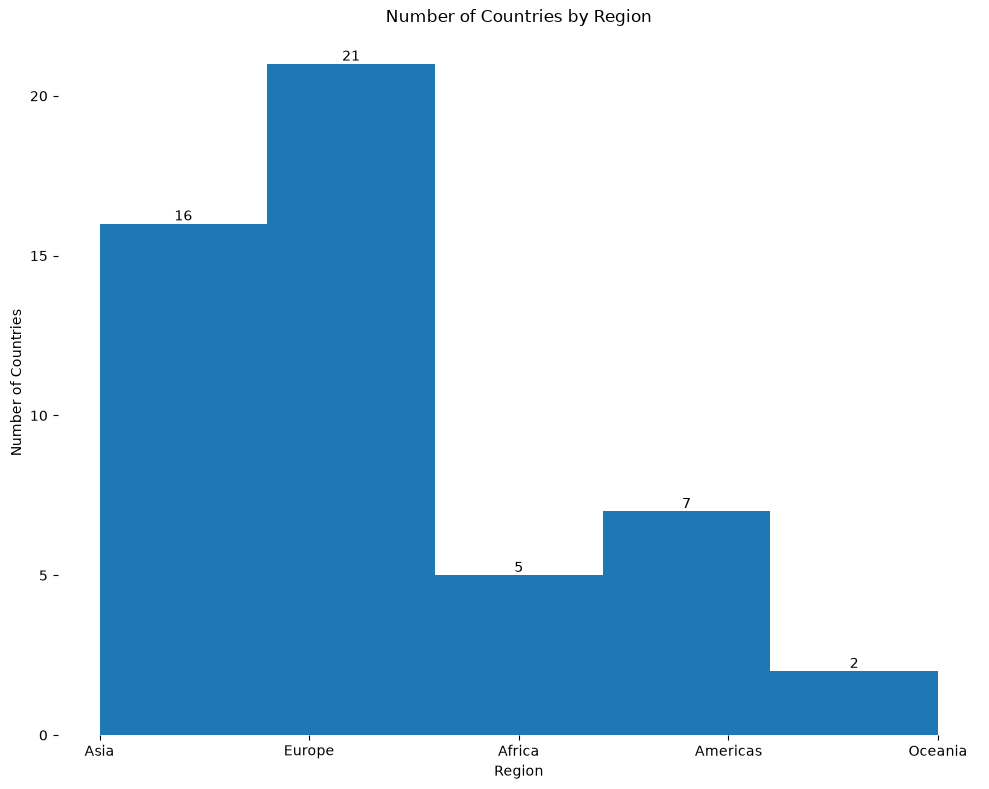

In [153]:
plt.figure(figsize=(10,8))# Makes the Graph Larger to fit all of the information

plt.hist(countries_df['region'], #Uses Matplotlib to call the region information from the created dataframe
         bins=5, # Creates only 5 bins
          align = 'mid' # Aligns them to the middle
         )

plt.bar_label(plt.gca().containers[0]) # Places the Number of Countrys above each bin

plt.gca().spines[:].set_visible(False)
plt.xlabel('Region')#names the x axis
plt.ylabel('Number of Countries')#names the y axis
plt.title('Number of Countries by Region')#names the title
plt.yticks(range(0, 25, 5))# Changed the max y value and the interval

plt.tight_layout()
plt.show()

# Chart 1 Revised

In this chart I removed the spines as they were unnessesary. I tightend the space between each bin and changed the max y vallue and change intervall to make it faster and easier to read. Finally I put the number of countrys above the bins to be able to quickly tell the value of each bin.

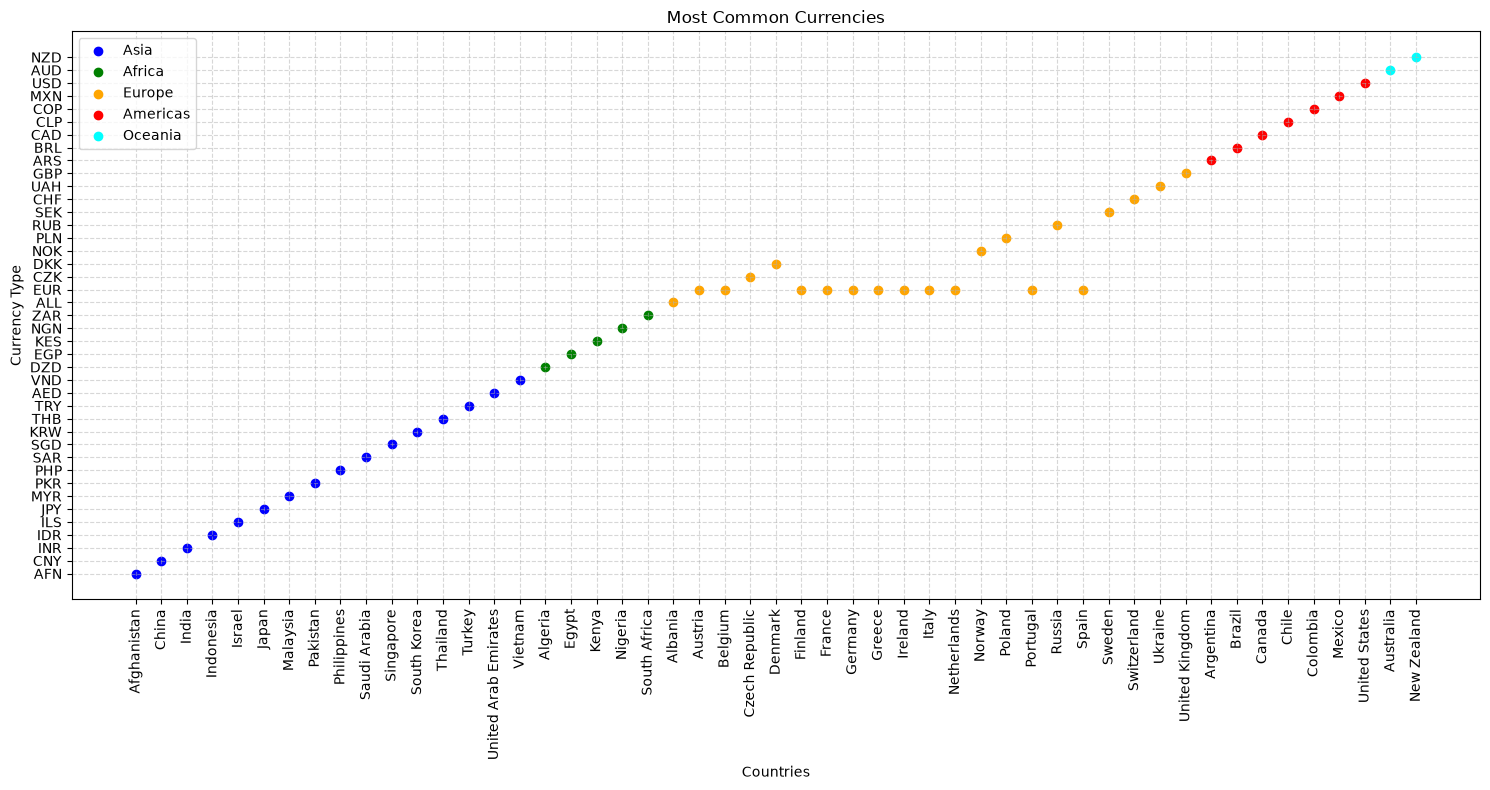

In [143]:
plt.figure(figsize=(15,8))# Makes the Graph Larger to fit all of the information

plt.scatter(countries_df[countries_df['region'] == 'Asia']['name'], # Creates Scatter Graph with name and currency for countries in asia
            countries_df[countries_df['region'] == 'Asia']['currency'],
            color = 'blue',# Colors the countries in asia blue
            label = 'Asia'
           )
plt.scatter(countries_df[countries_df['region'] == 'Africa']['name'],# Creates Scatter Graph with name and currency for countries in Africa
            countries_df[countries_df['region'] == 'Africa']['currency'],
            color = 'green',# Colors the countries in Africa Green
            label = 'Africa'
           )
plt.scatter(countries_df[countries_df['region'] == 'Europe']['name'],# Creates Scatter Graph with name and currency for countries in Europe
            countries_df[countries_df['region'] == 'Europe']['currency'],
            color = 'orange',# Colors the countries in Europe Orange
            label = 'Europe'
           )
plt.scatter(countries_df[countries_df['region'] == 'Americas']['name'],# Creates Scatter Graph with name and currency for countries in Americas
            countries_df[countries_df['region'] == 'Americas']['currency'],
            color = 'red',# Colors the countries in Americas Red
            label = 'Americas'
           )   
plt.scatter(countries_df[countries_df['region'] == 'Oceania']['name'],# Creates Scatter Graph with name and currency for countries in Oceania
            countries_df[countries_df['region'] == 'Oceania']['currency'],
            color = 'cyan',# Colors the countries in Oceania Cyan
            label = 'Oceania'
           )  
          

plt.xlabel('Countries') # X axis lable
plt.ylabel('Currency Type')# Y axis lable
plt.title('Most Common Currencies') # Graph Title
plt.xticks(rotation=90)# Rotates X Axis Labels so you can read them
plt.grid(True, linestyle='--', alpha=0.5) # Creates a grid to be used to make the graph more readible when there is a shared x value
plt.legend() # Creats a legend key for legiblity
plt.tight_layout()# Tightens layout to fit better due to large amount fo x and y axis items
plt.show()

# Chart 2 Revised

In this chart I added color coding for each region and a legend to help people understand the relationships. I also added a semi-transparent grid to see wich values are the same and diffrent.

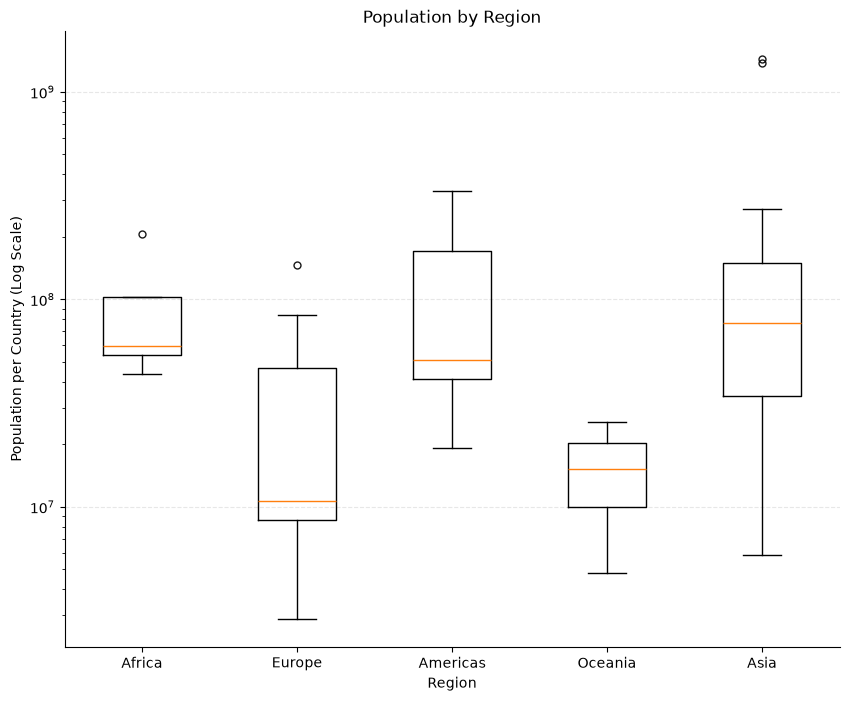

In [167]:
plt.figure(figsize=(10,8))# Makes the Graph Larger to fit all of the information

# Creates Varibles that containt the population info of countries with in each region
Africa = countries_df[countries_df['region'] == 'Africa']['population']
Europe = countries_df[countries_df['region'] == 'Europe']['population']
Americas = countries_df[countries_df['region'] == 'Americas']['population']
Oceania = countries_df[countries_df['region'] == 'Oceania']['population']
Asia = countries_df[countries_df['region'] == 'Asia']['population']

# Creates a boxplot using the Regional Population Varibles then names the diffrent charts accordingly
plt.boxplot( [Africa, Europe, Americas, Oceania, Asia],
    tick_labels=["Africa","Europe","Americas","Oceania","Asia"])

plt.grid(axis='y', linestyle='--', alpha=0.3)# Creates Lines to help understand the scale

plt.gca().spines['top'].set_visible(False)# removes the right and top spines
plt.gca().spines['right'].set_visible(False)

plt.yscale('log') # Scales the Y Axis to be more comprehendible due to its large size

# Titles Graph Elements
plt.xlabel("Region")
plt.ylabel("Population per Country (Log Scale)")
plt.title("Population by Region")

plt.show()

# Chart 3 Revised

For this chart I changed the y value to be logarithmic to me more readible I also removed the right and top spine to create less cludder. I also added some lines to help the readiblity of the scale.

In [182]:
from statsmodels.formula.api import ols #imports OLS function as ols


countries_df['region2'] = countries_df['region'].apply( #Creates a New column that seperates asian countrys from all others
    lambda x: 'Asia' if x == 'Asia' else 'Other Regions'
)


model = ols('population ~ C(region2)', data=countries_df).fit() # compares the population of asian countries to the populations of all others using ols


print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             population   R-squared:                       0.108
Model:                            OLS   Adj. R-squared:                  0.090
Method:                 Least Squares   F-statistic:                     5.954
Date:                Mon, 16 Nov 2026   Prob (F-statistic):             0.0183
Time:                        00:59:41   Log-Likelihood:                -1059.7
No. Observations:                  51   AIC:                             2123.
Df Residuals:                      49   BIC:                             2127.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

In [184]:
print(model.params)
print(model.pvalues)

Intercept                      2.489408e+08
C(region2)[T.Other Regions]   -1.922203e+08
dtype: float64
Intercept                      0.000383
C(region2)[T.Other Regions]    0.018347
dtype: float64


---

When Looking at this OLS model where country population is used as the dependent varible and region2 ( Asia vs all other countries) is the independent vareible you find that the average approximate population of countries in Asia is 248,940,800 people while countries outside of Asia average approximately 56,720,500 people or -192,220,300 people less on average.

We know that this data is statisticaly significant because the P value is 0.018 which falls bellow 0.05

This confirms that Asian countries are statisticly more likly to on average have a higher population than other countries.

---

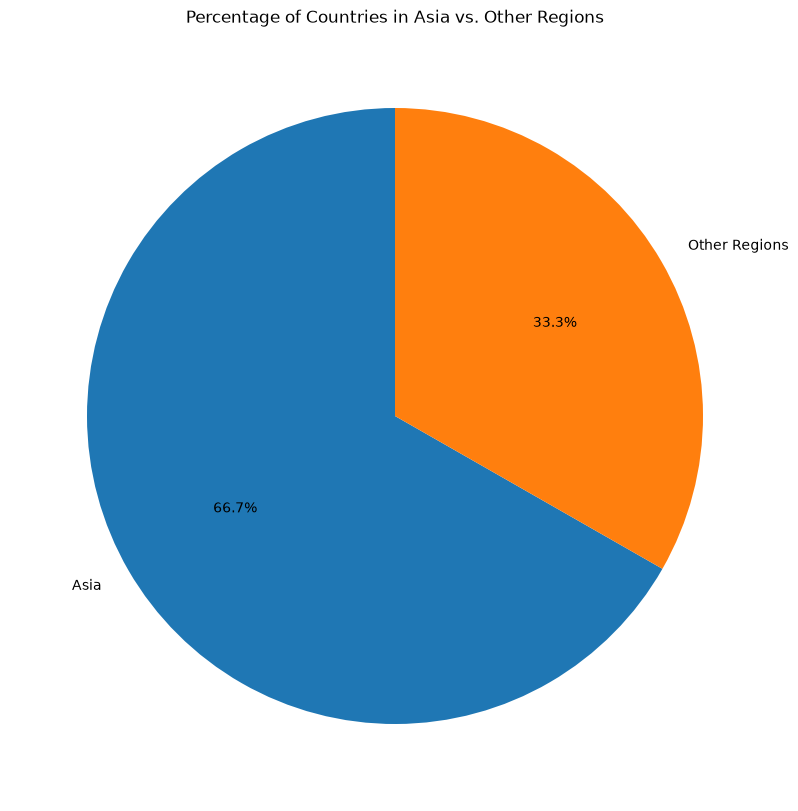

In [189]:
countries_df['region2'] = countries_df['region'].apply( #Creates a New column that seperates asian countrys from all others
    lambda x: 'Asia' if x == 'Asia' else 'Other Regions'
)

# Groups all the countries in to the establised Asia or other categories then add all the populations together to plot
countries_df.groupby('region2')['population'].sum().plot(  
    kind='pie', # Makes a Pie Chart
    autopct='%1.1f%%', # Displays the percentage of the categories on the chart
    figsize=(10,10),# Sets the fig size for readblity
    startangle=90 # Sets the start angle of first line between sections as verticle and in the middle
)

plt.title('Percentage of Countries in Asia vs. Other Regions')
plt.show()

---

Looking at this additinal chart we see that 66.7% of the the total population provided by this dataset is made up by countries in Asia

---

# Conclusions & Reflection
---

I learned alot about how to think about the columns given with a dataset in order to find out the information yo are looking for. For example the way that you almose need two diffrent charts that tell you simmilar but slightly diffrent information to make sure that you are getting the whole picture on of what the data is telling you.

In relation to my question I found out...

    Asia does by far contain the greatest population

    Asia makes up 66.7% of the total population (of this dataset)

    On average there is approximately 248,940,800 people per Asian country which is 192,220,300 more than the average for all other countries outside of Asia

    The only currency that is shared with in this dataset is the Euro which is standard in 11 countries with in Europe

    Europe contains the most amount of countries with in this data set at 21 countries followed by Asia with 16

---

So for my Hypothesis most of the evidence supports the claims made with in it. 

    Asia for sure has the greatest population and there is not a standard currency throughout Asia. 

    The the total population percentage of Asia is actualy 16.7% higher than the 50% that I had assumend

    However, Asia despite having the largest population does not contain the most amount of countries that would actually go to Europe

---

I feel that for my question was best awnsered by the boxplot. It gave the mose information helped me understand that I was corect about the majority of my hypothesis. Though seeing the population comparison of each region.

---

The statstical analysis did help me to pin point the specific values of populations as well as the way they compaired with each other. This helped to renforce and collaborate the findings of the boxplot.

---


The Limitations with in the data set are as follows

    The set only contains 51 countries which is around 1/3 of the worlds total countries.

    The set seems to be slightly bias towards Europe (As seen through country count vs poulation count)

    The set seems bias againt Afican countries do to the minimal amount of included countries

    This dataset does not include a date so may be outdated by this point

    This dataset does not include sources so may not be correct

---

My analysis failed to capture the specific values of population for regions other than Asia as well as seperate countries' information 

--- 

Addtional data that would have helped this investegation would be the missing countries as well as what is the most used currency in each country not what their national currency is.

---

## AI DISCLAIMER

I used the help of AI in order to troubleshoot and find the correct syntax for select cells.